### Regression

### Agenda
in this notebook , covering the following concepts with the help of business usecase

* use case : Regression
* Regression Algorithm
* Types of model Evluation
* Gradient Descent
* Types of Gradient Descent
* use case : Stochastic Gradeint Descent (SGD)

####  use case:
Note: At first, with the help of a use case, we are going to perform all the basic steps to reach the model training and predicition part

### **Problem Statement:**
Google Play Store team is about to launch a new feature wherein, certain apps that are promising are boosted in visibility. The boost will
manifest in multiple ways including higher priority in recommendations sections (“Similar apps”, “You might also like”, “New and updated
games”). These will also get a boost in search results visibility. This feature will help bring more attention to newer apps that have the
potential.

##### **Analysis to be done:**
The problem is to identify the apps that are going to be good for Google to promote. App ratings, which are provided by the customers,
are always great indicators of the goodness of the app. The problem reduces to: predict which apps will have high ratings.


#### **Dataset**
Google Play Store data (googleplaystore.csv)
Link: https://www.dropbox.com/sh/i06ohrau3ucfgbm/AACeYXumL56543KnDNQFlj8ma?dl=0

## Data Dictionary

| Variables | Description |
|-----------|-------------|
| **App** | Application name |
| **Category** | Category to which the app belongs |
| **Rating** | Overall user rating of the app |
| **Reviews** | Number of user reviews for the app |
| **Size** | Size of the app |
| **Installs** | Number of user downloads/installs for the app |
| **Type** | Paid or Free |
| **Price** | Price of the app |
| **Content Rating** | Age group the app is targeted at - Children / Mature 21+ / Adult |
| **Genres** | An app can belong to multiple genres (apart from its main category). For example, a musical family game will belong to Music, Game, Family genres |
| **Last Updated** | Date when the app was last updated on Play Store |
| **Current Ver** | Current version of the app available on Play Store |
| **Android Ver** | Minimum required Android version |

### **Soultion**

#### **Import Libraries**

In [1]:
#importing the libraries
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

#### import and check the Dataset


In [2]:
#Load the dataset
data = pd.read_csv("googleplaystore.csv")


In [3]:
data

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content_Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art_&_Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art_&_Design_Pretend_Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art_&_Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art_&_Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art_&_Design_Creativity,"June 20, 2018",1.1,4.4 and up
...,...,...,...,...,...,...,...,...,...,...,...,...,...
10836,Sya9a Maroc - FR,FAMILY,4.5,38,53M,"5,000+",Free,0,Everyone,Education,"July 25, 2017",1.48,4.1 and up
10837,Fr. Mike Schmitz Audio Teachings,FAMILY,5.0,4,3.6M,100+,Free,0,Everyone,Education,"July 6, 2018",1,4.1 and up
10838,Parkinson Exercices FR,MEDICAL,NaN,3,9.5M,"1,000+",Free,0,Everyone,Medical,"January 20, 2017",1,2.2 and up
10839,The SCP Foundation DB fr nn5n,BOOKS_AND_REFERENCE,4.5,114,Varies with device,"1,000+",Free,0,Mature_17+,Books_&_Reference,"January 19, 2015",Varies with device,Varies with device


#### Basic Checks

In [4]:
#Top 5 Records
data.head()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content_Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.1,159,19M,"10,000+",Free,0,Everyone,Art_&_Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.9,967,14M,"500,000+",Free,0,Everyone,Art_&_Design_Pretend_Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.7,87510,8.7M,"5,000,000+",Free,0,Everyone,Art_&_Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.5,215644,25M,"50,000,000+",Free,0,Teen,Art_&_Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.3,967,2.8M,"100,000+",Free,0,Everyone,Art_&_Design_Creativity,"June 20, 2018",1.1,4.4 and up


In [5]:
#Bottom 5 records 
data.tail()

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content_Rating,Genres,Last Updated,Current Ver,Android Ver
10836,Sya9a Maroc - FR,FAMILY,4.5,38,53M,"5,000+",Free,0,Everyone,Education,"July 25, 2017",1.48,4.1 and up
10837,Fr. Mike Schmitz Audio Teachings,FAMILY,5.0,4,3.6M,100+,Free,0,Everyone,Education,"July 6, 2018",1,4.1 and up
10838,Parkinson Exercices FR,MEDICAL,NaN,3,9.5M,"1,000+",Free,0,Everyone,Medical,"January 20, 2017",1,2.2 and up
10839,The SCP Foundation DB fr nn5n,BOOKS_AND_REFERENCE,4.5,114,Varies with device,"1,000+",Free,0,Mature_17+,Books_&_Reference,"January 19, 2015",Varies with device,Varies with device
10840,iHoroscope - 2018 Daily Horoscope & Astrology,LIFESTYLE,4.5,398307,19M,"10,000,000+",Free,0,Everyone,Lifestyle,"July 25, 2018",Varies with device,Varies with device


In [6]:
#General information about the dataset
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10841 entries, 0 to 10840
Data columns (total 13 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   App             10841 non-null  object 
 1   Category        10841 non-null  object 
 2   Rating          9367 non-null   float64
 3   Reviews         10841 non-null  object 
 4   Size            10841 non-null  object 
 5   Installs        10841 non-null  object 
 6   Type            10840 non-null  object 
 7   Price           10841 non-null  object 
 8   Content_Rating  10840 non-null  object 
 9   Genres          10841 non-null  object 
 10  Last Updated    10841 non-null  object 
 11  Current Ver     10833 non-null  object 
 12  Android Ver     10838 non-null  object 
dtypes: float64(1), object(12)
memory usage: 1.1+ MB


In [7]:
#Check for the datatype
data.dtypes

App                object
Category           object
Rating            float64
Reviews            object
Size               object
Installs           object
Type               object
Price              object
Content_Rating     object
Genres             object
Last Updated       object
Current Ver        object
Android Ver        object
dtype: object

In [8]:
#dimension of the dataset
data.shape

(10841, 13)

In [9]:
#List of all the columns in the dataset
data.columns

Index(['App', 'Category', 'Rating', 'Reviews', 'Size', 'Installs', 'Type',
       'Price', 'Content_Rating', 'Genres', 'Last Updated', 'Current Ver',
       'Android Ver'],
      dtype='object')

#### Finding the null values 

In [10]:
# Finding the Null Values 
data.isnull().sum()

App                  0
Category             0
Rating            1474
Reviews              0
Size                 0
Installs             0
Type                 1
Price                0
Content_Rating       1
Genres               0
Last Updated         0
Current Ver          8
Android Ver          3
dtype: int64

### Observations:

* The **Rating** column is considered the **target variable** for this analysis.
* The remaining **12 columns** can be considered as **input/features**.
* The dataset contains a total of **13 columns**.
* The **Rating** column is of **float** datatype, while the remaining columns are of **object** datatype.
* The dataset contains **10,841 rows and 13 columns**, with dimensions of **(10841, 13)**.
* The columns containing missing/null values are **Rating, Type, Content Rating, Current Ver, and Android Ver**.

#### Treating of the Null values 

In [11]:
# Dropping the  records with the Null values 
# This is done because rating is our Target  variable 
data.dropna(how ="any" ,inplace =True )  

In [12]:
# Verify the Dropping
data.shape

(9360, 13)

In [13]:
data.isnull().sum()

App               0
Category          0
Rating            0
Reviews           0
Size              0
Installs          0
Type              0
Price             0
Content_Rating    0
Genres            0
Last Updated      0
Current Ver       0
Android Ver       0
dtype: int64

#### Handling the Variables

##### 1.Clean the price column

In [14]:
data["Price"]

0        0
1        0
2        0
3        0
4        0
        ..
10834    0
10836    0
10837    0
10839    0
10840    0
Name: Price, Length: 9360, dtype: object

In [15]:
data.Price.value_counts()
#data.Price.value_counts()[:5]

Price
0        8715
$2.99     114
$0.99     106
$4.99      70
$1.99      59
         ... 
$2.95       1
$2.90       1
$1.97       1
$2.56       1
$1.20       1
Name: count, Length: 73, dtype: int64

#### Observations:
* in Price column some have dollars and some have 0
* First , let's modify the column to take 0 if value is 0 ,else take the first letter onwards
  

In [16]:
data.Price = data.Price.map(lambda x : 0 if x == "0"  else float(x[1:]))
data.Price.value_counts()

Price
0.00    8715
2.99     114
0.99     106
4.99      70
1.99      59
        ... 
2.95       1
2.90       1
1.97       1
2.56       1
1.20       1
Name: count, Length: 73, dtype: int64

#### **There are others columns with the numeric data**
1. Reviews
2. Installs
3. Size

#### 2. Convert reviews to numeric

In [17]:
data.Reviews.dtype
data.Reviews

0           159
1           967
2         87510
3        215644
4           967
          ...  
10834         7
10836        38
10837         4
10839       114
10840    398307
Name: Reviews, Length: 9360, dtype: object

In [18]:
# Convert the Reviews to Numeric value 
data.Reviews  = data.Reviews.astype("float")


In [19]:
data.Reviews.dtype

dtype('float64')

In [20]:
data.Reviews.describe()

count    9.360000e+03
mean     5.143767e+05
std      3.145023e+06
min      1.000000e+00
25%      1.867500e+02
50%      5.955000e+03
75%      8.162750e+04
max      7.815831e+07
Name: Reviews, dtype: float64

#### 3.Handling the  installs column

In [21]:
# Handling the missing values 
data.Installs.value_counts()

Installs
1,000,000+        1576
10,000,000+       1252
100,000+          1150
10,000+           1009
5,000,000+         752
1,000+             712
500,000+           537
50,000+            466
5,000+             431
100,000,000+       409
100+               309
50,000,000+        289
500+               201
500,000,000+        72
10+                 69
1,000,000,000+      58
50+                 56
5+                   9
1+                   3
Name: count, dtype: int64

#### **Observation**

We need to remove the + and comma signs

#### Definfing the values using Function



In [22]:
def clean_install(val):
    return int(val.replace("+","").replace(",",""))

In [23]:
data.Installs = data.Installs.map(clean_install)

In [24]:
data.Installs.value_counts()

Installs
1000000       1576
10000000      1252
100000        1150
10000         1009
5000000        752
1000           712
500000         537
50000          466
5000           431
100000000      409
100            309
50000000       289
500            201
500000000       72
10              69
1000000000      58
50              56
5                9
1                3
Name: count, dtype: int64

#### 4.Handel the app size field


In [25]:
data.Size.value_counts()

Size
Varies with device    1637
14M                    165
12M                    161
15M                    159
11M                    159
                      ... 
467k                     1
676k                     1
552k                     1
582k                     1
619k                     1
Name: count, Length: 413, dtype: int64

In [26]:
#Handling the app size Field 

def change_size(size):
    if  "M" in size :
        x = size[:-1]
        x= float(x) * 1000
        return x
        
    elif  "k" in size:
        x = size[:-1]
        x= float(x)
        return x
    else:
        return None

In [27]:
data.Size = data.Size.map(change_size)

In [28]:
data.Size.value_counts()

Size
14000.0    165
12000.0    161
15000.0    159
11000.0    159
13000.0    157
          ... 
467.0        1
676.0        1
552.0        1
582.0        1
619.0        1
Name: count, Length: 411, dtype: int64

In [29]:
data.Size.isnull().sum()

np.int64(1637)

In [30]:
data.shape

(9360, 13)

In [31]:
data.Size.describe()

count      7723.000000
mean      22970.456105
std       23449.628935
min           8.500000
25%        5300.000000
50%       14000.000000
75%       33000.000000
max      100000.000000
Name: Size, dtype: float64

In [32]:
#To  see the the missing values 
data[data.Size.isnull()]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content_Rating,Genres,Last Updated,Current Ver,Android Ver
37,Floor Plan Creator,ART_AND_DESIGN,4.1,36639.0,NaN,5000000,Free,0.0,Everyone,Art_&_Design,"July 14, 2018",Varies with device,2.3.3 and up
42,Textgram - write on photos,ART_AND_DESIGN,4.4,295221.0,NaN,10000000,Free,0.0,Everyone,Art_&_Design,"July 30, 2018",Varies with device,Varies with device
52,Used Cars and Trucks for Sale,AUTO_AND_VEHICLES,4.6,17057.0,NaN,1000000,Free,0.0,Everyone,Auto_&_Vehicles,"July 30, 2018",Varies with device,Varies with device
67,Ulysse Speedometer,AUTO_AND_VEHICLES,4.3,40211.0,NaN,5000000,Free,0.0,Everyone,Auto_&_Vehicles,"July 30, 2018",Varies with device,Varies with device
68,REPUVE,AUTO_AND_VEHICLES,3.9,356.0,NaN,100000,Free,0.0,Everyone,Auto_&_Vehicles,"May 25, 2018",Varies with device,Varies with device
...,...,...,...,...,...,...,...,...,...,...,...,...,...
10713,My Earthquake Alerts - US & Worldwide Earthquakes,WEATHER,4.4,3471.0,NaN,100000,Free,0.0,Everyone,Weather,"July 24, 2018",Varies with device,Varies with device
10725,Posta App,MAPS_AND_NAVIGATION,3.6,8.0,NaN,1000,Free,0.0,Everyone,Maps_&_Navigation,"September 27, 2017",Varies with device,4.4 and up
10765,Chat For Strangers - Video Chat,SOCIAL,3.4,622.0,NaN,100000,Free,0.0,Mature_17+,Social,"May 23, 2018",Varies with device,Varies with device
10826,Frim: get new friends on local chat rooms,SOCIAL,4.0,88486.0,NaN,5000000,Free,0.0,Mature_17+,Social,"March 23, 2018",Varies with device,Varies with device


In [33]:
#Imputing the Missing size values 
data["Size"] = data["Size"].fillna(data["Size"].median())

In [34]:
data["Size"].isnull().sum()

np.int64(0)

#### Sanity Checks

#### 1.Average number of rating should be  between the 1 and 5 , as only these values are allowed on the Play store ,Drop any number of rows  that have this range

In [35]:
#Checking the rating 
data.Rating.describe()

count    9360.000000
mean        4.191838
std         0.515263
min         1.000000
25%         4.000000
50%         4.300000
75%         4.500000
max         5.000000
Name: Rating, dtype: float64

#### Observation 
Min is 1 and Max is 5 ,None of the values are having rating outside the range

#### 2.Reviews Should not be more than the installs as only those who installed can review the app

In [36]:
#Checking the Counting the rows
data[data.Reviews > data.Installs]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content_Rating,Genres,Last Updated,Current Ver,Android Ver
2454,KBA-EZ Health Guide,MEDICAL,5.0,4.0,25000.0,1,Free,0.00,Everyone,Medical,"August 2, 2018",1.0.72,4.0.3 and up
4663,Alarmy (Sleep If U Can) - Pro,LIFESTYLE,4.8,10249.0,14000.0,10000,Paid,2.49,Everyone,Lifestyle,"July 30, 2018",Varies with device,Varies with device
5917,Ra Ga Ba,GAME,5.0,2.0,20000.0,1,Paid,1.49,Everyone,Arcade,"February 8, 2017",1.0.4,2.3 and up
6700,Brick Breaker BR,GAME,5.0,7.0,19000.0,5,Free,0.00,Everyone,Arcade,"July 23, 2018",1,4.1 and up
7402,Trovami se ci riesci,GAME,5.0,11.0,6100.0,10,Free,0.00,Everyone,Arcade,"March 11, 2017",0.1,2.3 and up
8591,DN Blog,SOCIAL,5.0,20.0,4200.0,10,Free,0.00,Teen,Social,"July 23, 2018",1,4.0 and up
10697,Mu.F.O.,GAME,5.0,2.0,16000.0,1,Paid,0.99,Everyone,Arcade,"March 3, 2017",1,2.3 and up


In [37]:
len(data[data.Reviews > data.Installs])

7

In [38]:
data = data[data.Reviews <= data.Installs].copy()

In [39]:
data.shape

(9353, 13)

#### 3. For the apps (Type == "Free") , the proce should not be >0  ,Drop such rows

In [40]:
data[(data.Type == "Free") & (data.Price > 0)]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content_Rating,Genres,Last Updated,Current Ver,Android Ver


#### Observation
we Dont have any such values 

In [41]:
data.Type.value_counts()

Type
Free    8711
Paid     642
Name: count, dtype: int64

In [42]:
len(data[(data.Type == "Free") & (data.Price > 0)])

0

#### EDA

##### Boxplot :Price 

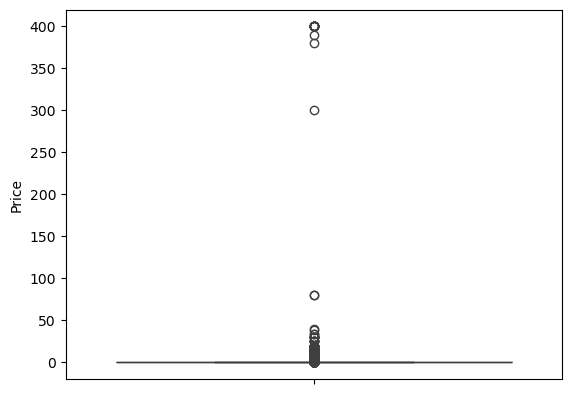

In [43]:
#Are there any outliers ? Think about the price of usual apps on play store 
sns.boxplot(data["Price"])
plt.show()

#### Box plot :Reviews

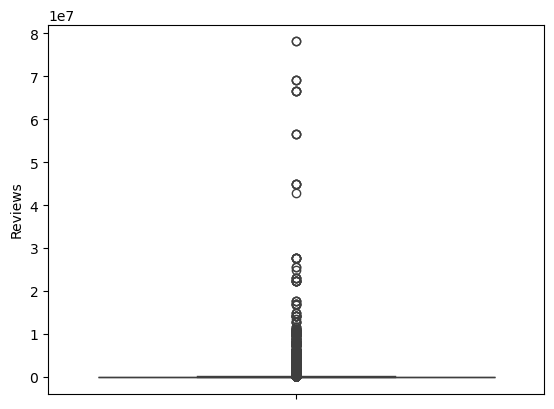

In [44]:
#Are there any apps with very high number of reviews ? Do the values seems right
sns.boxplot(data.Reviews)
plt.show()


##### Checking the Distribution and Skewness
How are the rating Distributed ? Is it more toward higher rating?


#### Distributed Rating


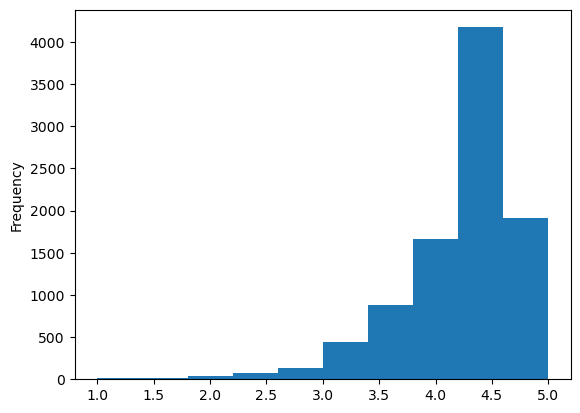

In [45]:
data.Rating.plot.hist()
plt.show()

#### Histogram :Size


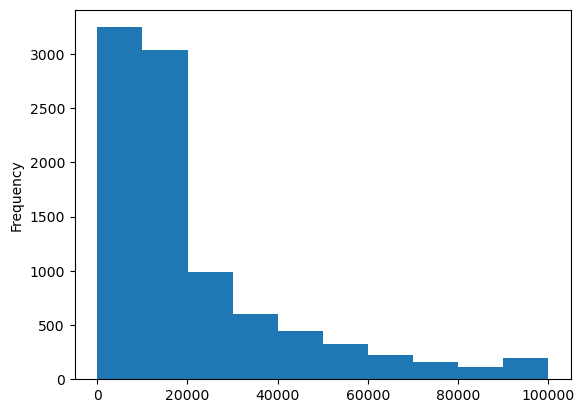

In [46]:
data.Size.plot.hist()
plt.show()


#### Pair Plot 

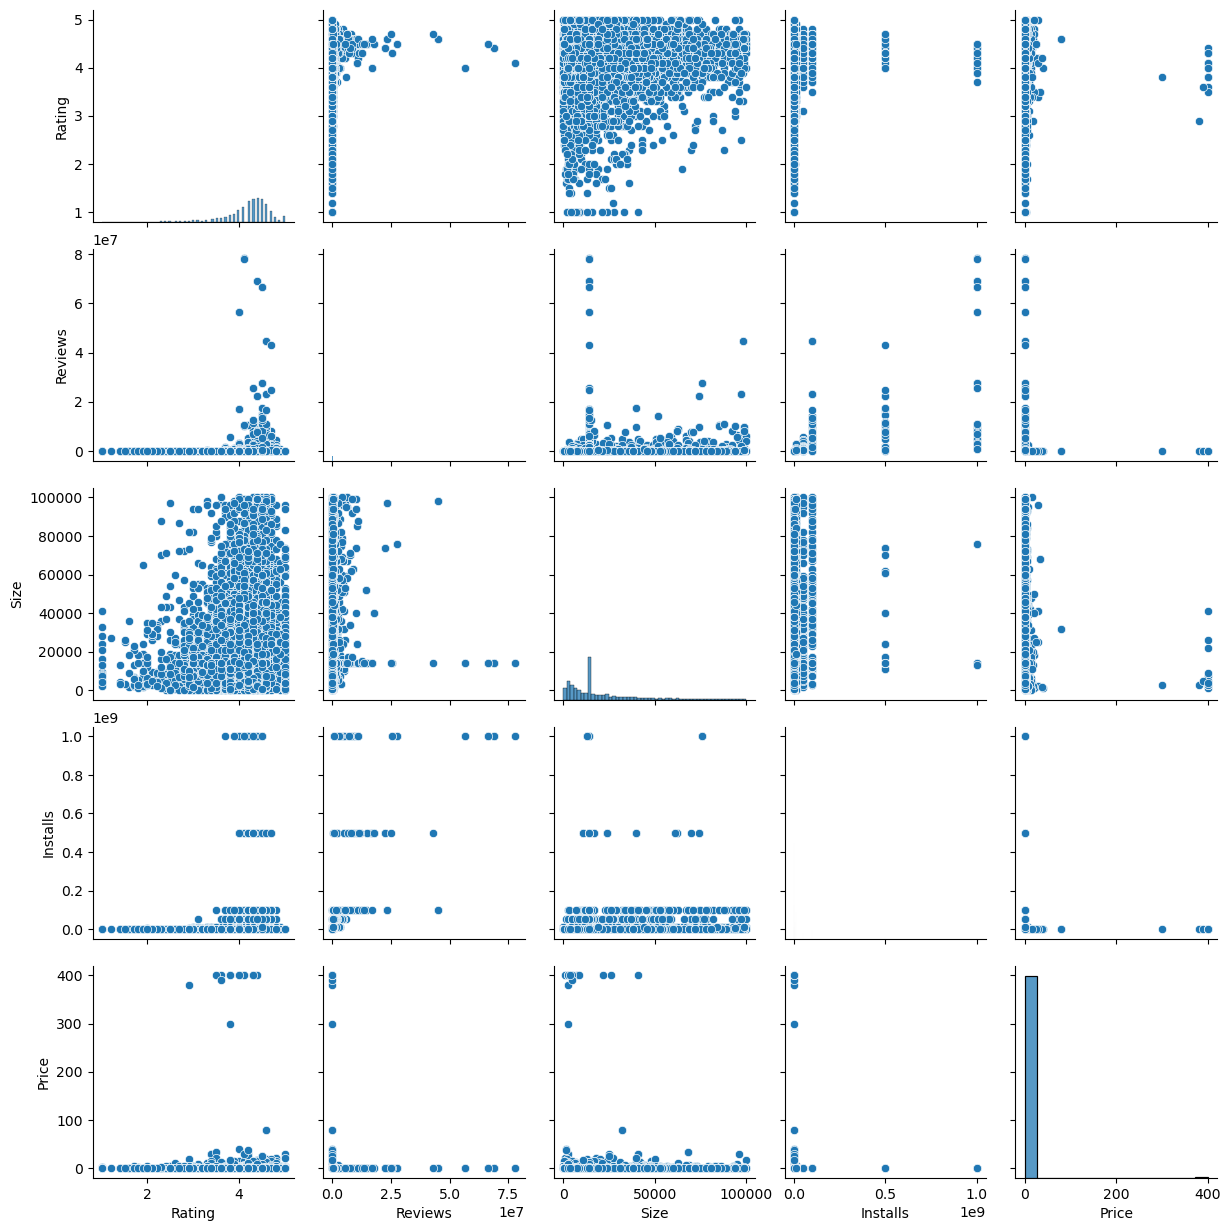

In [47]:
sns.pairplot(data=data)
plt.show()

#####  Outlier Treatment:


#### 1.Price
From the box plot, it seems like there are some apps with very high prices. A price of $200 for an application on the Play Store is very high
and suspicious. Check the records that have very high price: Is 200 a high price

In [48]:
#checking the records 
data[data.Price > 200 ]


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content_Rating,Genres,Last Updated,Current Ver,Android Ver
4197,most expensive app (H),FAMILY,4.3,6.0,1500.0,100,Paid,399.99,Everyone,Entertainment,"July 16, 2018",1,7.0 and up
4362,💎 I'm rich,LIFESTYLE,3.8,718.0,26000.0,10000,Paid,399.99,Everyone,Lifestyle,"March 11, 2018",1.0.0,4.4 and up
4367,I'm Rich - Trump Edition,LIFESTYLE,3.6,275.0,7300.0,10000,Paid,400.00,Everyone,Lifestyle,"May 3, 2018",1.0.1,4.1 and up
5351,I am rich,LIFESTYLE,3.8,3547.0,1800.0,100000,Paid,399.99,Everyone,Lifestyle,"January 12, 2018",2,4.0.3 and up
5354,I am Rich Plus,FAMILY,4.0,856.0,8700.0,10000,Paid,399.99,Everyone,Entertainment,"May 19, 2018",3,4.4 and up
5355,I am rich VIP,LIFESTYLE,3.8,411.0,2600.0,10000,Paid,299.99,Everyone,Lifestyle,"July 21, 2018",1.1.1,4.3 and up
5356,I Am Rich Premium,FINANCE,4.1,1867.0,4700.0,50000,Paid,399.99,Everyone,Finance,"November 12, 2017",1.6,4.0 and up
5357,I am extremely Rich,LIFESTYLE,2.9,41.0,2900.0,1000,Paid,379.99,Everyone,Lifestyle,"July 1, 2018",1,4.0 and up
5358,I am Rich!,FINANCE,3.8,93.0,22000.0,1000,Paid,399.99,Everyone,Finance,"December 11, 2017",1,4.1 and up
5359,I am rich(premium),FINANCE,3.5,472.0,965.0,5000,Paid,399.99,Everyone,Finance,"May 1, 2017",3.4,4.4 and up


In [49]:
len(data[data.Price > 200 ])

15

In [50]:
data = data[data.Price <= 200].copy() 

In [51]:
data.shape

(9338, 13)

#### 3.Installs 

##### There seem to be some outliers in this field too. Apps having a very high number of installs should be dropped from the analysis. Find out
the different percentiles – 10, 25, 50, 70, 90, 99.
Decide a threshold as the cutoff for outliers and drop records having values more than the threshold

In [52]:
data.Installs.quantile([0.1,0.25,0.5,0.70,0.9,0.99])

0.10         1000.0
0.25        10000.0
0.50       500000.0
0.70      5000000.0
0.90     10000000.0
0.99    500000000.0
Name: Installs, dtype: float64

#### Observations:
Looks like there are just 1% of apps having more than 100M installs 
we need to drop these .


In [53]:
#Dropping the apps with more than 100M installs
#data[data.Installs >= 1000000000]
len(data[data.Installs >= 1000000000])

58

In [54]:
data= data[data.Installs <= 1000000000].copy()
data.shape

(9338, 13)

In [55]:
#Importing Warnings
import warnings
warnings.filterwarnings("ignore")

#### Bi-Variate analysis

Let’s look at how the available predictors relate to the variable of interest, i.e., our target variable rating. Make scatter plots (for numeric
features) and box plots (for character features) to assess the relationhips between rating and the other features.

#### 1.Make Scatter plot / join plot for Rating vs Price

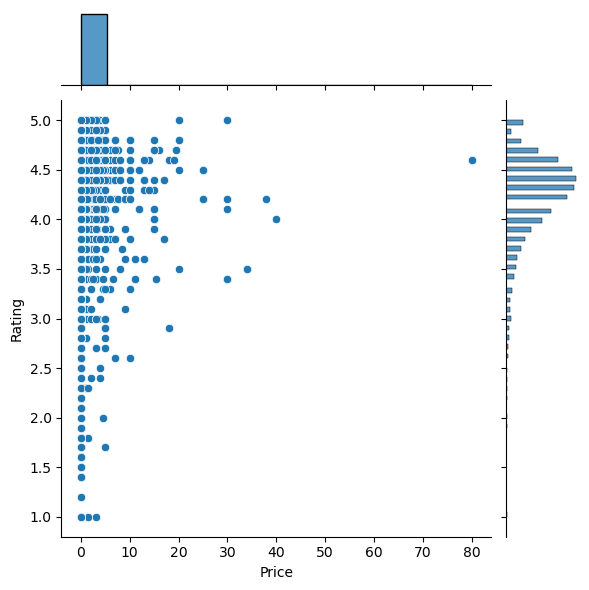

In [56]:
#What Pattern do you Observe ? Does Rating increase with Price
sns.jointplot(x="Price",y= "Rating",data=data)
plt.show()

#### 2.Make Scatter plot/joinplot for Rating vs Size

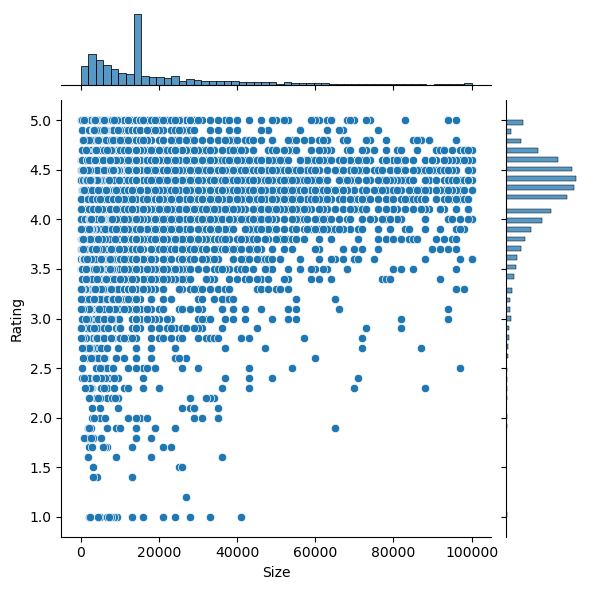

In [57]:
#Are heavier apps rated better ?
sns.jointplot(x= "Size",y= "Rating",data=data)
plt.show()

#### 3.Make Scatter plot/ jointplot for Rating vs Reviews

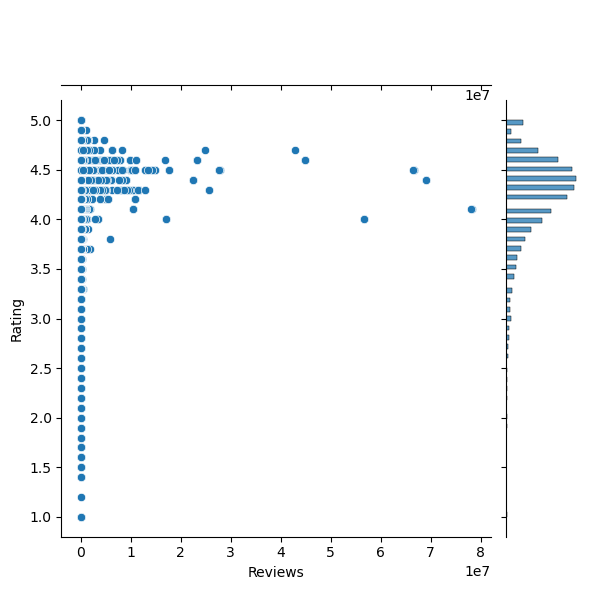

In [58]:
#Does mpre review mean a better rating always?
sns.jointplot(x="Reviews" ,y= "Rating" ,data=data)
plt.show()

#### 4.Make boxplot for Rating vs content Rating


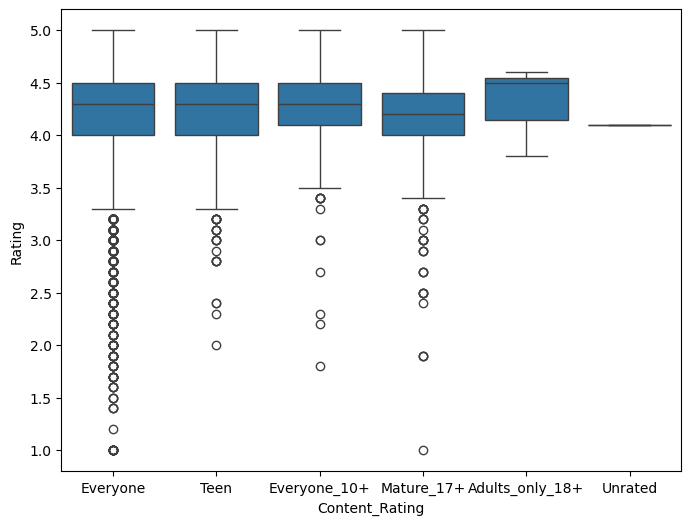

In [59]:
#Is there any differece  in the rating ?  Are some types liked better ?
plt.figure(figsize =[8,6])
sns.boxplot(x ="Content_Rating",y= "Rating",data=data)
plt.show()

#### 5.Make boxplot for Rating vs category

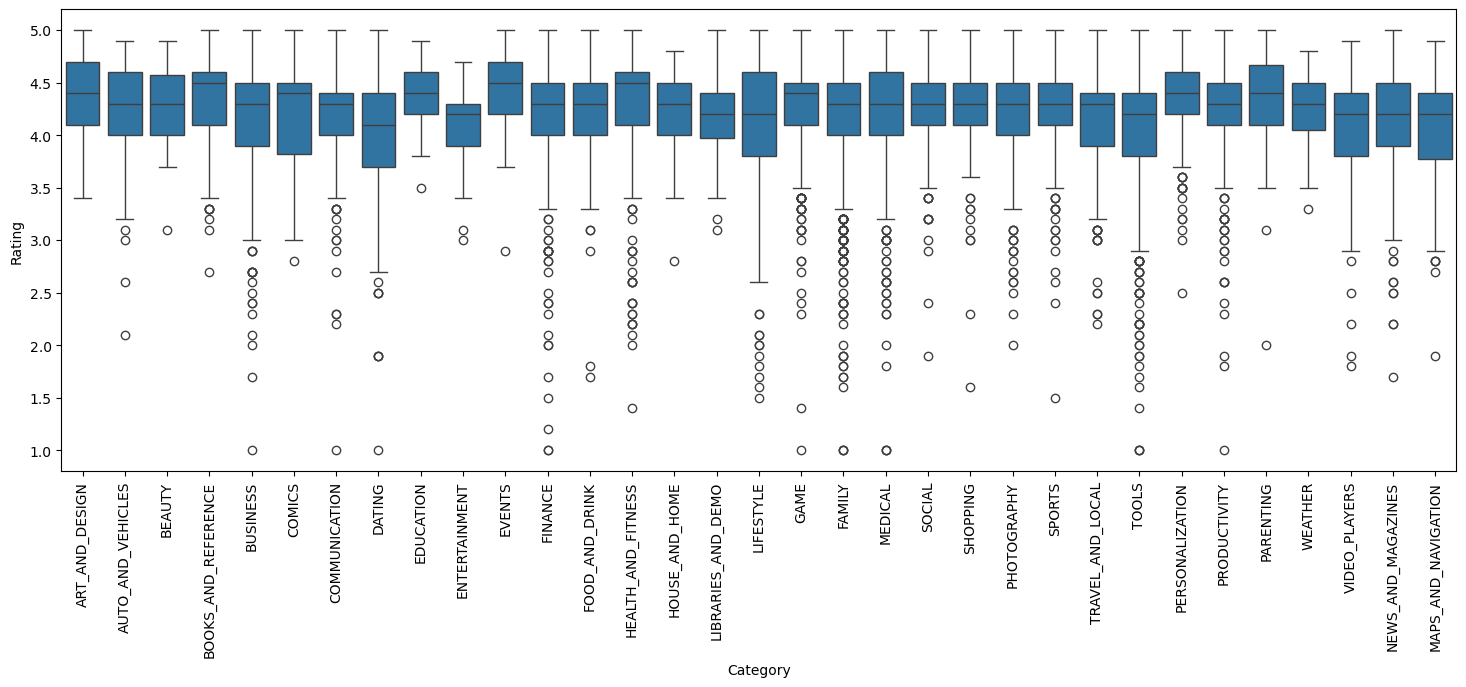

In [60]:
#Which Genre has the best ratings?
plt.figure(figsize =[18,6])
g =sns.boxplot(x="Category",y= "Rating",data=data)
plt.xticks(rotation=90)
plt.show()

#### Feature Engineering :Review Rate

In [64]:
# Create Review Rate
data["Review_Rate"] = data["Reviews"] / data["Installs"]

# Check the new feature
data["Review_Rate"].describe()

count    9338.000000
mean        0.035976
std         0.057156
min         0.000007
25%         0.009300
50%         0.019284
75%         0.040000
max         1.000000
Name: Review_Rate, dtype: float64

In [65]:
data["Review_Rate"] = np.log1p(data["Review_Rate"])

In [66]:
data[["Reviews", "Installs", "Review_Rate"]].describe()

,Reviews,Installs,Review_Rate
count,9.338000e+03,9.338000e+03,9338.000000
mean,5.155865e+05,1.795092e+07,0.034071
std,3.148627e+06,9.136968e+07,0.048439
min,1.000000e+00,5.000000e+00,0.000007
25%,1.880000e+02,1.000000e+04,0.009257
50%,6.009000e+03,5.000000e+05,0.019101
75%,8.247100e+04,5.000000e+06,0.039221
max,7.815831e+07,1.000000e+09,0.693147


#### Log transform Price

In [68]:
data["Log_Price"] = np.log1p(data["Price"])

In [69]:
data.drop("Price", axis=1, inplace=True)

### **Pre-Processing the Dataset**

#### **1.Make a copy of the dataset**

In [70]:
#Making  a copy
data1 =data.copy()

#### **2.Apply log transformation (np.log1p) to Reviews and Installs**

Reviews and Installs have some values that are still relatively very high. Before building a linear regression model, you need to reduce the
skew.

In [71]:
#Reducing the Skew
data1.Installs.describe()

count    9.338000e+03
mean     1.795092e+07
std      9.136968e+07
min      5.000000e+00
25%      1.000000e+04
50%      5.000000e+05
75%      5.000000e+06
max      1.000000e+09
Name: Installs, dtype: float64

In [72]:
data1.Reviews = data1.Reviews.apply(np.log1p)


In [73]:
data1.Installs = data1.Installs.apply(np.log1p)

#### **3.Drop columns app,Last updated ,curretn Ver, and And Android Ver**
These variables are not  useful for out task

In [74]:
data1.dtypes

App                object
Category           object
Rating            float64
Reviews           float64
Size              float64
Installs          float64
Type               object
Content_Rating     object
Genres             object
Last Updated       object
Current Ver        object
Android Ver        object
Review_Rate       float64
Log_Price         float64
dtype: object

In [75]:
#Dropping the Variables that are not useful for our task 
data1.drop(["App","Last Updated","Current Ver","Android Ver"],axis=1,inplace=True)
data1.shape

(9338, 10)

#### **Dummy Columns**
Get dummy columns for Category, Genres, and Content Rating. This needs to be done as the models do not understand categorical data,
and all data should be numeric. Dummy encoding is one way to convert character fields to numeric fields. Name of the dataframe should
be data2

In [76]:
data2 = pd.get_dummies(data1,drop_first =True)


In [77]:
data2.columns

Index(['Rating', 'Reviews', 'Size', 'Installs', 'Review_Rate', 'Log_Price',
       'Category_AUTO_AND_VEHICLES', 'Category_BEAUTY',
       'Category_BOOKS_AND_REFERENCE', 'Category_BUSINESS',
       ...
       'Genres_Tools', 'Genres_Tools_Education', 'Genres_Travel_&_Local',
       'Genres_Travel_&_Local_Action_&_Adventure', 'Genres_Trivia',
       'Genres_Video_Players_&_Editors',
       'Genres_Video_Players_&_Editors_Creativity',
       'Genres_Video_Players_&_Editors_Music_&_Video', 'Genres_Weather',
       'Genres_Word'],
      dtype='object', length=158)

In [78]:
data2.shape

(9338, 158)

In [79]:
data2.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9338 entries, 0 to 10840
Columns: 158 entries, Rating to Genres_Word
dtypes: bool(152), float64(6)
memory usage: 1.9 MB


#### **Train - Test - Split**
Let us distribute the data into **training** and **test** dataset

In [80]:
from sklearn.model_selection import train_test_split

In [81]:
#train_test_split
df_train,df_test =train_test_split(data2 ,train_size= 0.7,random_state =100)

In [82]:
df_train.shape,df_test.shape

((6536, 158), (2802, 158))

In [83]:
df_train

,Rating,Reviews,Size,Installs,Review_Rate,Log_Price,Category_AUTO_AND_VEHICLES,Category_BEAUTY,Category_BOOKS_AND_REFERENCE,Category_BUSINESS,...,Genres_Tools,Genres_Tools_Education,Genres_Travel_&_Local,Genres_Travel_&_Local_Action_&_Adventure,Genres_Trivia,Genres_Video_Players_&_Editors,Genres_Video_Players_&_Editors_Creativity,Genres_Video_Players_&_Editors_Music_&_Video,Genres_Weather,Genres_Word
10162,4.4,4.025352,1400.0,8.517393,0.010940,0.000000,False,False,False,False,...,True,False,False,False,False,False,False,False,False,False
5036,3.5,4.356709,1200.0,6.908755,0.074179,3.044046,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4737,4.4,5.327876,33000.0,10.819798,0.004092,0.000000,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
551,4.2,12.656272,14000.0,16.118096,0.030890,0.000000,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1365,4.4,9.461799,55000.0,13.122365,0.025391,0.000000,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
363,4.3,14.712041,14000.0,18.420681,0.024215,0.000000,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
81,4.4,9.627009,37000.0,13.815512,0.015054,0.000000,True,False,False,False,...,False,False,False,False,False,False,False,False,False,False
9150,4.0,11.150161,45000.0,13.122365,0.130281,0.000000,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
7808,4.6,14.222723,14000.0,18.420681,0.014914,0.000000,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [84]:
df_test

,Rating,Reviews,Size,Installs,Review_Rate,Log_Price,Category_AUTO_AND_VEHICLES,Category_BEAUTY,Category_BOOKS_AND_REFERENCE,Category_BUSINESS,...,Genres_Tools,Genres_Tools_Education,Genres_Travel_&_Local,Genres_Travel_&_Local_Action_&_Adventure,Genres_Trivia,Genres_Video_Players_&_Editors,Genres_Video_Players_&_Editors_Creativity,Genres_Video_Players_&_Editors_Music_&_Video,Genres_Weather,Genres_Word
811,4.3,10.775785,21000.0,13.815512,0.046738,0.000000,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
10666,4.6,2.197225,9000.0,6.908755,0.007968,0.000000,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4932,3.4,7.280008,9700.0,11.512935,0.014396,0.000000,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4153,4.0,15.044995,14000.0,20.723266,0.003414,0.000000,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3977,3.9,3.218876,64000.0,6.908755,0.023717,1.095273,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9092,4.7,7.940228,9800.0,11.512935,0.027683,0.000000,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4839,4.1,11.458068,14000.0,13.815512,0.090445,0.000000,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
8918,4.4,5.624018,14000.0,10.819798,0.005505,0.000000,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
5621,4.0,10.761132,36000.0,15.424949,0.009386,0.000000,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


#### Let us Seperate the dataframes into x_train,y_train,x_test,y_test

In [85]:
y_train = df_train.pop("Rating")
x_train =df_train

In [86]:
x_train.head()

,Reviews,Size,Installs,Review_Rate,Log_Price,Category_AUTO_AND_VEHICLES,Category_BEAUTY,Category_BOOKS_AND_REFERENCE,Category_BUSINESS,Category_COMICS,...,Genres_Tools,Genres_Tools_Education,Genres_Travel_&_Local,Genres_Travel_&_Local_Action_&_Adventure,Genres_Trivia,Genres_Video_Players_&_Editors,Genres_Video_Players_&_Editors_Creativity,Genres_Video_Players_&_Editors_Music_&_Video,Genres_Weather,Genres_Word
10162,4.025352,1400.0,8.517393,0.010940,0.000000,False,False,False,False,False,...,True,False,False,False,False,False,False,False,False,False
5036,4.356709,1200.0,6.908755,0.074179,3.044046,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4737,5.327876,33000.0,10.819798,0.004092,0.000000,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
551,12.656272,14000.0,16.118096,0.030890,0.000000,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1365,9.461799,55000.0,13.122365,0.025391,0.000000,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [87]:
y_test =df_test.pop("Rating")
x_test= df_test

In [88]:
x_test.head()

,Reviews,Size,Installs,Review_Rate,Log_Price,Category_AUTO_AND_VEHICLES,Category_BEAUTY,Category_BOOKS_AND_REFERENCE,Category_BUSINESS,Category_COMICS,...,Genres_Tools,Genres_Tools_Education,Genres_Travel_&_Local,Genres_Travel_&_Local_Action_&_Adventure,Genres_Trivia,Genres_Video_Players_&_Editors,Genres_Video_Players_&_Editors_Creativity,Genres_Video_Players_&_Editors_Music_&_Video,Genres_Weather,Genres_Word
811,10.775785,21000.0,13.815512,0.046738,0.000000,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
10666,2.197225,9000.0,6.908755,0.007968,0.000000,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4932,7.280008,9700.0,11.512935,0.014396,0.000000,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4153,15.044995,14000.0,20.723266,0.003414,0.000000,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3977,3.218876,64000.0,6.908755,0.023717,1.095273,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


#### **Regression Alogorithms:**

##### **Import StatsModel Library  for Linear Regression**

In [89]:
#Importing the Statsmodel library
import statsmodels.api as sm

In [90]:
x_train.info()
print("-"*10)
y_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 6536 entries, 10162 to 6058
Columns: 157 entries, Reviews to Genres_Word
dtypes: bool(152), float64(5)
memory usage: 1.2 MB
----------
<class 'pandas.core.series.Series'>
Index: 6536 entries, 10162 to 6058
Series name: Rating
Non-Null Count  Dtype  
--------------  -----  
6536 non-null   float64
dtypes: float64(1)
memory usage: 102.1 KB


In [91]:
x_train =x_train.astype(float)
y_train =y_train.astype(float)

In [92]:
x_test = x_test.astype(float)
y_test =y_test.astype(float)

In [93]:
x_train =sm.add_constant(x_train)
x_test =sm.add_constant(x_test)

In [94]:
#Applying the Linear Regression 
Model1 =sm.OLS(y_train,x_train)
Model1 = Model1.fit()

print(Model1.summary())

                            OLS Regression Results                            
Dep. Variable:                 Rating   R-squared:                       0.174
Model:                            OLS   Adj. R-squared:                  0.159
Method:                 Least Squares   F-statistic:                     11.20
Date:                Mon, 05 Oct 2026   Prob (F-statistic):          5.05e-185
Time:                        20:00:37   Log-Likelihood:                -4149.7
No. Observations:                6536   AIC:                             8543.
Df Residuals:                    6414   BIC:                             9371.
Df Model:                         121                                         
Covariance Type:            nonrobust                                         
                                                   coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------

In [95]:
Model1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                 Rating   R-squared:                       0.174
Model:                            OLS   Adj. R-squared:                  0.159
Method:                 Least Squares   F-statistic:                     11.20
Date:                Mon, 05 Oct 2026   Prob (F-statistic):          5.05e-185
Time:                        20:00:39   Log-Likelihood:                -4149.7
No. Observations:                6536   AIC:                             8543.
Df Residuals:                    6414   BIC:                             9371.
Df Model:                         121                                         
Covariance Type:            nonrobust                                         
================================================================================================================
                                                   coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------------------------------
const                                            4.6164      0.487      9.473      0.000       3.661       5.572
Reviews                                          0.1478      0.008     18.076      0.000       0.132       0.164
Size                                          2.697e-08   3.23e-07      0.084      0.933   -6.06e-07     6.6e-07
Installs                                        -0.1242      0.008    -14.944      0.000      -0.140      -0.108
Review_Rate                                      0.5830      0.189      3.084      0.002       0.212       0.954
Log_Price                                       -0.0338      0.034     -1.004      0.315      -0.100       0.032
Category_AUTO_AND_VEHICLES                      -0.0240      0.205     -0.117      0.907      -0.425       0.377
Category_BEAUTY                                  0.0755      0.206      0.366      0.714      -0.329       0.480
Category_BOOKS_AND_REFERENCE                     0.0540      0.203      0.266      0.790      -0.344       0.452
Category_BUSINESS                               -0.0500      0.202     -0.247      0.805      -0.447       0.347
Category_COMICS                                  0.1610      0.311      0.518      0.604      -0.448       0.770
Category_COMMUNICATION                          -0.0859      0.202     -0.424      0.671      -0.483       0.311
Category_DATING                                 -0.1467      0.203     -0.722      0.470      -0.545       0.252
Category_EDUCATION                              -0.3148      0.403     -0.781      0.435      -1.105       0.475
Category_ENTERTAINMENT                          -0.3397      0.403     -0.843      0.399      -1.129       0.450
Category_EVENTS                                  0.0837      0.206      0.406      0.685      -0.320       0.488
Category_FAMILY                                 -0.2298      0.399     -0.576      0.565      -1.012       0.553
Category_FINANCE                                -0.0648      0.202     -0.320      0.749      -0.462       0.332
Category_FOOD_AND_DRINK                         -0.0682      0.203     -0.335      0.737      -0.467       0.330
Category_GAME                                   -0.1287      0.402     -0.320      0.749      -0.918       0.660
Category_HEALTH_AND_FITNESS                     -0.0218      0.202     -0.108      0.914      -0.419       0.375
Category_HOUSE_AND_HOME                         -0.0305      0.204     -0.150      0.881      -0.431       0.370
Category_LIBRARIES_AND_DEMO                     -0.0018      0.205     -0.009      0.993      -0.403       0.400
Category_LIFESTYLE                              -0.1378      0.310     -0.444      0.657      -0.746       0.470
Category_MAPS_AND_NAVIGATION    

In [96]:
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

# Predictions
y_train_pred = Model1.predict(x_train)
y_test_pred = Model1.predict(x_test)

# R² Score
train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

# RMSE
train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

# Display results
print("Training R²:", train_r2)
print("Testing R²:", test_r2)

print("Training RMSE:", train_rmse)
print("Testing RMSE:", test_rmse)

Training R²: 0.17447378130964863
Testing R²: 0.1477247110747134
Training RMSE: 0.4565574469515009
Testing RMSE: 0.5013465338321993


####  create a basline model

In [97]:
from sklearn.dummy import DummyRegressor

baseline = DummyRegressor(strategy="mean")

baseline.fit(x_train, y_train)

baseline_pred = baseline.predict(x_test)

baseline_r2 = r2_score(y_test, baseline_pred)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_pred)
)

print("Baseline R²:", baseline_r2)
print("Baseline RMSE:", baseline_rmse)

Baseline R²: -0.00031673920648334075
Baseline RMSE: 0.5431463139588287


### Try Random forest model 


In [98]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=300,
    random_state=100,
    n_jobs=-1
)

rf_model.fit(x_train, y_train)

RandomForestRegressor(n_estimators=300, n_jobs=-1, random_state=100)

In [99]:
rf_pred = rf_model.predict(x_test)

#### Evluate 


In [100]:
rf_r2 = r2_score(y_test, rf_pred)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_pred)
)

print("Random Forest R²:", rf_r2)
print("Random Forest RMSE:", rf_rmse)

Random Forest R²: 0.1343041063117728
Random Forest RMSE: 0.5052784163488135


#### Compare all the models

In [101]:
results = pd.DataFrame({
    "Model": [
        "Baseline",
        "OLS Regression",
        "Random Forest"
    ],
    
    "R2": [
        baseline_r2,
        test_r2,
        rf_r2
    ],
    
    "RMSE": [
        baseline_rmse,
        test_rmse,
        rf_rmse
    ]
})

results


,Model,R2,RMSE
0,Baseline,-0.000317,0.543146
1,OLS Regression,0.147725,0.501347
2,Random Forest,0.134304,0.505278


#### Actual VS Predicted plot

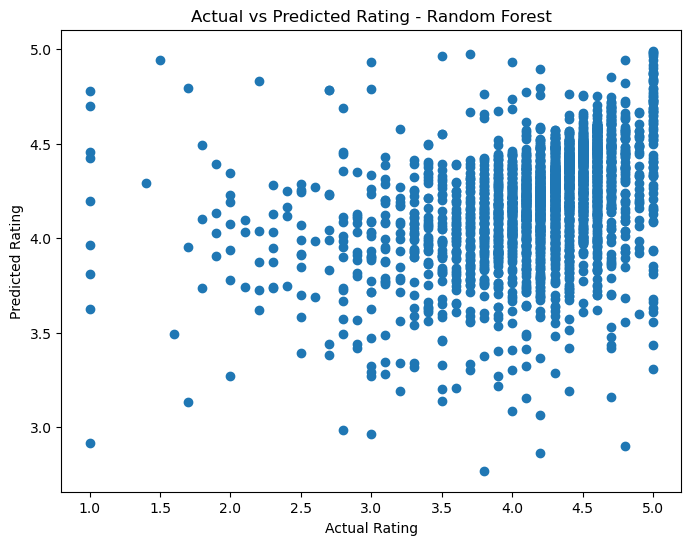

In [102]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.scatter(y_test, rf_pred)

plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")
plt.title("Actual vs Predicted Rating - Random Forest")

plt.show()

#### Feature Importance 


In [103]:
feature_importance = pd.DataFrame({
    "Feature": x_train.columns,
    "Importance": rf_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
4,Review_Rate,0.254676
1,Reviews,0.213040
2,Size,0.181643
3,Installs,0.038732
5,Log_Price,0.016925
80,Genres_Education,0.010240
16,Category_FAMILY,0.010009
93,Genres_Entertainment,0.009424
39,Content_Rating_Everyone,0.008700
101,Genres_Finance,0.008209


#### Plot the top 15 apps

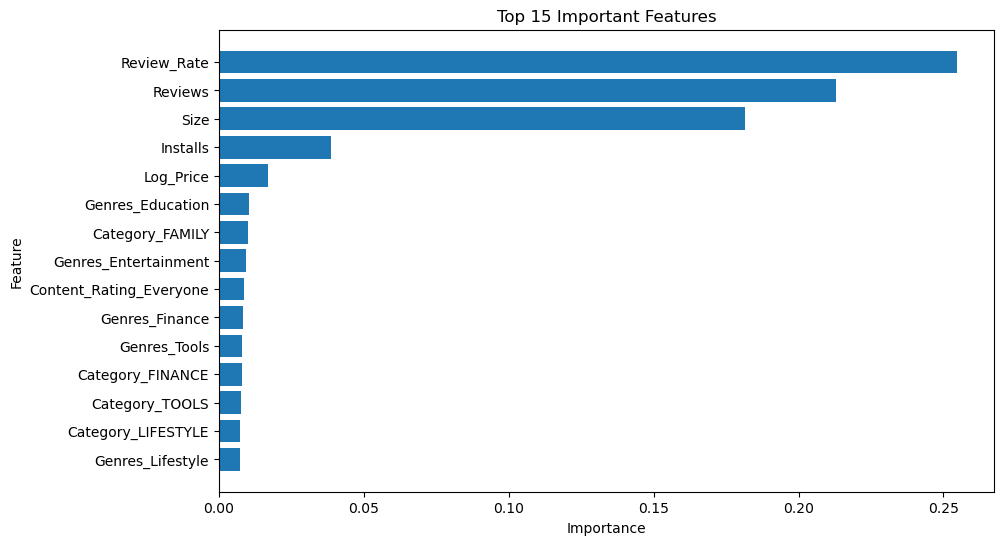

In [104]:
top_features = feature_importance.head(15)

plt.figure(figsize=(10,6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 15 Important Features")

plt.gca().invert_yaxis()

plt.show()

#### Gradient boost Model

In [106]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=100
)

gb_model.fit(x_train, y_train)

gb_pred = gb_model.predict(x_test)

gb_r2 = r2_score(y_test, gb_pred)

gb_rmse = np.sqrt(
    mean_squared_error(y_test, gb_pred)
)

print("Gradient Boosting R²:", gb_r2)
print("Gradient Boosting RMSE:", gb_rmse)

Gradient Boosting R²: 0.13787543259033674
Gradient Boosting RMSE: 0.5042351059752078


#### Final comparision of all the models 

In [107]:
results = pd.DataFrame({
    "Model": [
        "Baseline",
        "OLS Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    
    "R2": [
        baseline_r2,
        test_r2,
        rf_r2,
        gb_r2
    ],
    
    "RMSE": [
        baseline_rmse,
        test_rmse,
        rf_rmse,
        gb_rmse
    ]
})

results

,Model,R2,RMSE
0,Baseline,-0.000317,0.543146
1,OLS Regression,0.147725,0.501347
2,Random Forest,0.134304,0.505278
3,Gradient Boosting,0.137875,0.504235


### Check Residuals

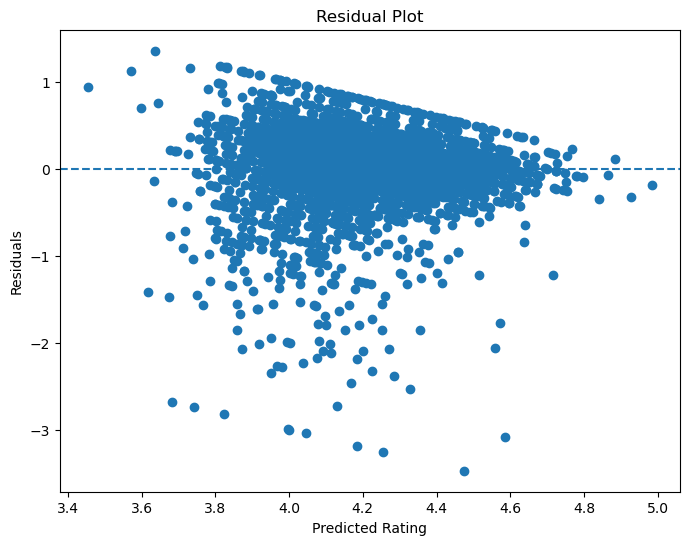

In [108]:
residuals = y_test - y_test_pred

plt.figure(figsize=(8,6))

plt.scatter(y_test_pred, residuals)

plt.axhline(y=0, linestyle="--")

plt.xlabel("Predicted Rating")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

#### Check Residual Distribution

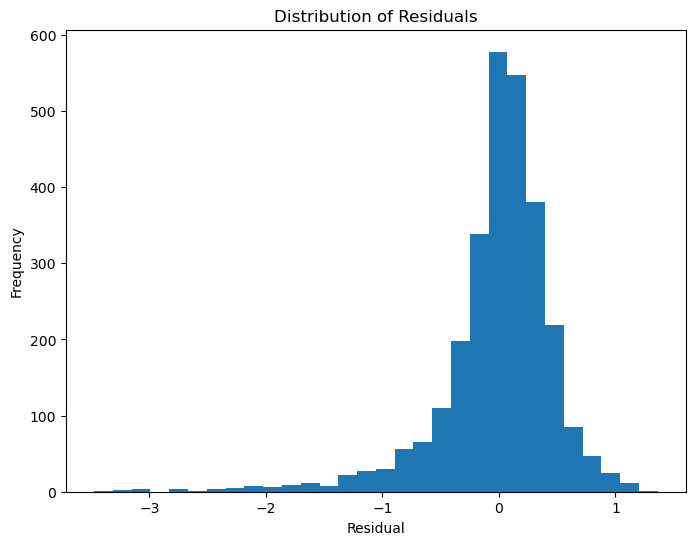

In [109]:
plt.figure(figsize=(8,6))

plt.hist(residuals, bins=30)

plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.title("Distribution of Residuals")

plt.show()

##### Conclusion 
Four approaches were evaluated: a baseline model, OLS Regression, Random Forest, and Gradient Boosting. OLS Regression achieved the highest test R² of 0.1477 and the lowest test RMSE of 0.5013. Therefore, OLS Regression was selected as the best-performing model among the evaluated approaches.